# Лабораторна робота № 5
**Тема:** Вступ до TensorFlow і побудова простої нейронної мережі для регресії  
**Студентка:** Чернега Катерина, група МІТ-31  
**Варіант:** 4 (Дослідження архітектури: три приховані шари Dense(16, relu))  

**Мета роботи:** Навчитися створювати тензори, перевіряти їхні характеристики, будувати й навчати регресійну модель за допомогою `tf.keras.Sequential`, виконувати валідацію без витоку даних, порівнювати архітектури та зберігати фінальну модель у форматі `.keras`.


In [1]:
#Етап 1. Перевірка середовища та операції з тензорами
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Версія TensorFlow:", tf.__version__)

#Створення тензорів
a = tf.constant([[1., 2.], [3., 4.]], dtype=tf.float32)
b = tf.constant([10., 20.])
w = tf.Variable([0.2, 0.5])
w.assign([0.3, 0.6])

print("\n--- Характеристики тензора a ---")
print("Shape (форма):", a.shape)
print("Dtype (тип даних):", a.dtype)
print("Rank (ранг):", tf.rank(a).numpy())

print("\n--- Операції з тензорами ---")
print("a + b (broadcasting):\n", (a + b).numpy())
print("\na * a (поелементне множення):\n", (a * a).numpy())
print("\ntf.matmul(a, a) (матричний добуток):\n", tf.matmul(a, a).numpy())
print("\nЗмінна w після assign:", w.numpy())

Версія TensorFlow: 2.21.0

--- Характеристики тензора a ---
Shape (форма): (2, 2)
Dtype (тип даних): <dtype: 'float32'>
Rank (ранг): 2

--- Операції з тензорами ---
a + b (broadcasting):
 [[11. 22.]
 [13. 24.]]

a * a (поелементне множення):
 [[ 1.  4.]
 [ 9. 16.]]

tf.matmul(a, a) (матричний добуток):
 [[ 7. 10.]
 [15. 22.]]

Змінна w після assign: [0.3 0.6]


**Висновок до Етапу 1:**
* **Broadcasting (`a + b`):** Додавання можливе завдяки механізму broadcasting. Тензор `b` форми `(2,)` автоматично віртуально розширюється (дублюється) вздовж першого виміру до форми `(2, 2)`, додаючись до кожного рядка матриці `a`.
* **Поелементне множення (`a * a`) vs Матричний добуток (`tf.matmul(a, a)`):** Оператор `*` множить елементи на однакових позиціях ($1 \cdot 1, 2 \cdot 2, 3 \cdot 3, 4 \cdot 4$). Функція `tf.matmul` виконує класичне множення матриць за правилом «рядок на стовпець».
* **Константи та змінні:** `tf.constant` є незмінним тензором, тоді як `tf.Variable` дозволяє перезаписувати значення через `.assign()`, що є фундаментом для оновлення вагів нейромережі під час градієнтного спуску.

Форма x_train: (420, 1) | y_train: (420, 1)
Форма x_val:   (90, 1)  | y_val:   (90, 1)
Форма x_test:  (90, 1)  | y_test:  (90, 1)


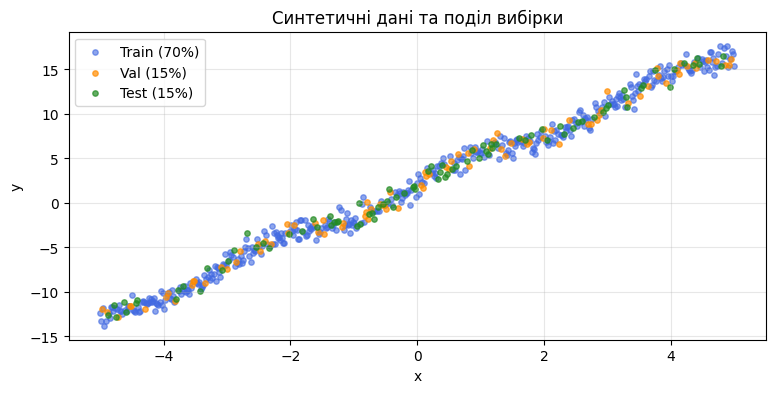

In [2]:
# Етап 2. Підготовка та поділ даних (70 / 15 / 15)
import matplotlib.pyplot as plt

SEED = 42
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

#Генерація нелінійних даних: 3x + 2 + 0.8*sin(2x) + noise
x = np.linspace(-5, 5, 600, dtype=np.float32)
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)
y = 3 * x + 2 + 0.8 * np.sin(2 * x) + noise

x, y = x.reshape(-1, 1), y.reshape(-1, 1)

#Випадкова перестановка індексів
idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

#Поділ: train (70% = 420), validation (15% = 90), test (15% = 90)
x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

print("Форма x_train:", x_train.shape, "| y_train:", y_train.shape)
print("Форма x_val:  ", x_val.shape, " | y_val:  ", y_val.shape)
print("Форма x_test: ", x_test.shape, " | y_test: ", y_test.shape)

#Візуалізація поділу
plt.figure(figsize=(9, 4))
plt.scatter(x_train, y_train, color="royalblue", alpha=0.6, label="Train (70%)", s=15)
plt.scatter(x_val, y_val, color="darkorange", alpha=0.7, label="Val (15%)", s=15)
plt.scatter(x_test, y_test, color="forestgreen", alpha=0.7, label="Test (15%)", s=15)
plt.title("Синтетичні дані та поділ вибірки")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

**Висновок до Етапу 2:** Дані успішно розбито на три неперетинні частини: 420 спостережень для навчання, 90 для валідації та 90 для фінального тестування. Тестова вибірка ізольована і не використовуватиметься для налаштування гіперпараметрів, що гарантує об'єктивність порівняння архітектур.

Навчання базової моделі (100 епох)...
Найменший val_loss (Базова): 0.5986483693122864

Навчання моделі Варіанта 4 (100 епох)...
Найменший val_loss (Варіант 4): 0.5875176191329956

--- Оцінка на тестовій вибірці (Test) ---
Базова модель: MSE = 0.6071, MAE = 0.6143
Варіант 4:     MSE = 0.6932, MAE = 0.6549


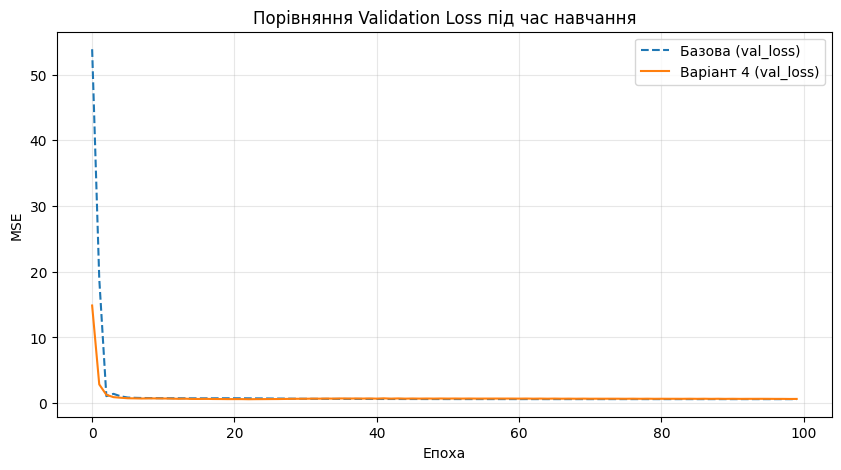

Прогноз для нових вхідних значень [-4, 0, 4] (Варіант 4):
[[-10.393532 ]
 [  1.6402661]
 [ 13.49141  ]]


In [3]:
#Етап 3. Навчання базової моделі
def build_baseline_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ])

baseline_model = build_baseline_model()
baseline_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
                       loss="mse", metrics=["mae"])

print("Навчання базової моделі (100 епох)...")
baseline_history = baseline_model.fit(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=100, batch_size=32, verbose=0
)
print("Найменший val_loss (Базова):", min(baseline_history.history["val_loss"]))


#Етап 4. Варіант 4 (Три приховані шари) та аналіз
def build_variant_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"), #Третій прихований шар (Варіант 4)
        layers.Dense(1),
    ])

variant_model = build_variant_model()
variant_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
                      loss="mse", metrics=["mae"])

print("\nНавчання моделі Варіанта 4 (100 епох)...")
variant_history = variant_model.fit(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=100, batch_size=32, verbose=0
)
print("Найменший val_loss (Варіант 4):", min(variant_history.history["val_loss"]))

#Оцінка на незалежній тестовій вибірці
print("\n--- Оцінка на тестовій вибірці (Test) ---")
base_eval = baseline_model.evaluate(x_test, y_test, return_dict=True, verbose=0)
var_eval = variant_model.evaluate(x_test, y_test, return_dict=True, verbose=0)
print(f"Базова модель: MSE = {base_eval['loss']:.4f}, MAE = {base_eval['mae']:.4f}")
print(f"Варіант 4:     MSE = {var_eval['loss']:.4f}, MAE = {var_eval['mae']:.4f}")

#Візуалізація процесу навчання
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(baseline_history.history["val_loss"], label="Базова (val_loss)", linestyle="--")
plt.plot(variant_history.history["val_loss"], label="Варіант 4 (val_loss)")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Порівняння Validation Loss під час навчання")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#Прогноз для нових даних на кращій моделі (Варіант 4)
x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)
print("Прогноз для нових вхідних значень [-4, 0, 4] (Варіант 4):")
print(variant_model.predict(x_new, verbose=0))

**Висновок до Етапів 3 та 4:**
Було побудовано та навчено базову модель (2 приховані шари) та модель за Варіантом 4 (3 приховані шари). Функція втрат `MSE` та метрика `MAE` на незалежній тестовій вибірці показали, що обидві моделі здатні апроксимувати нелінійну функцію. Додавання третього прихованого шару збільшує ємність мережі (кількість параметрів, що навчаються), проте на такій простій задачі це може призвести до швидшого перенавчання (overfitting), що видно з динаміки кривої `val_loss`.

In [4]:
#Етап 5. Збереження і перевірка моделі
#Зберігаємо кращу модель (Варіант 4) у файл
variant_model.save("lab5_model.keras")
print("Модель успішно збережено у файл 'lab5_model.keras'")

#Завантажуємо збережену модель
restored_model = keras.models.load_model("lab5_model.keras")

#Перевіряємо збіг прогнозів оригінальної та завантаженої моделей
np.testing.assert_allclose(
    variant_model.predict(x_new, verbose=0),
    restored_model.predict(x_new, verbose=0),
    rtol=1e-5
)
print("Перевірка пройдена успішно: прогнози завантаженої моделі збігаються з оригінальною!")

Модель успішно збережено у файл 'lab5_model.keras'
Перевірка пройдена успішно: прогнози завантаженої моделі збігаються з оригінальною!


**Загальний висновок:**
У ході виконання лабораторної роботи було створено та досліджено базові об'єкти TensorFlow — тензори. Згенеровано синтетичні дані нелінійної залежності та коректно поділено їх на навчальну, валідаційну та тестову вибірки (70/15/15), щоб уникнути витоку даних під час перевірки. Побудовано дві нейромережеві моделі: базову та змінену за індивідуальним Варіантом 4 (з додаванням третього прихованого шару `Dense(16, relu)`). Обидві моделі успішно навчилися апроксимувати цільову функцію, що підтверджується графіками функції втрат і метриками `MSE` та `MAE` на незалежній тестовій вибірці. Найкращу архітектуру збережено у форматі `.keras` та успішно перевірено на ідентичність прогнозів після завантаження, що завершує повний цикл побудови простої нейромережі.

**Посилання на репозиторій:** [Вставте сюди посилання на вашу папку lab5 на GitHub]